# Weight/mass loss Predictor for natural polymers

**Author:** Lab of Farm Structures
**Date:** 2026-11

## Import libraries

In [422]:
import pandas as pd
import kennard_stone as ks
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import math
import shap
from prince import FAMD
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, GroupKFold, KFold, RepeatedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
import seaborn as sns
from scipy.spatial.distance import cdist
from scipy.stats import chi2_contingency, spearmanr
from scipy.stats import pearsonr
from sklearn.base import clone
import warnings; warnings.filterwarnings("ignore")

## Load data

In [425]:
model_weight = 'weight_loss_cellulose_LM'

df_weight = pd.read_csv(f'{model_weight}.csv')
df_weight.tail()

,time_days,weight_loss_pct,study_id,sample_id,environment_class,polymer_family,polymer_wt_pct,additive1_type,additive1_wt_pct,morphology,cellulose_component
135,4.0,43.0,s014,s014m01,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose
136,7.0,51.0,s014,s014m01,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose
137,10.0,60.0,s014,s014m01,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose
138,15.0,69.0,s014,s014m01,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose
139,22.0,76.0,s014,s014m01,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose


## Exclude randomly one instance from multi-instance studies

In [428]:
np.random.seed(42)

# Count rows per Study_id and Instance
instance_row_counts = (
    df_weight.groupby(['study_id', 'sample_id'])
    .size()  # counts rows per Study_id-Instance
)

# Keep only instances with at least 5 rows
valid_instances = instance_row_counts[instance_row_counts >= 4]

# Study_ids with more than one instance
instance_counts = valid_instances.groupby('study_id').size()

# Keep only Study_ids with more than one valid instance
multi_study_ids = instance_counts[instance_counts > 3].index

# Randomly select ONE instance per such Study_id
excluded_instances = (
    df_weight[df_weight['study_id'].isin(multi_study_ids)]
    .groupby('study_id')['sample_id']
    .apply(lambda x: np.random.choice(x.unique()))
    .reset_index(name='Excluded_Instance')
)

# Merge back to create a row-aligned mask
df_with_exclusion = df_weight.merge(
    excluded_instances,
    on='study_id',
    how='left'
)

# Rows to exclude: those matching the randomly selected instance
exclude_mask = df_with_exclusion['sample_id'] == df_with_exclusion['Excluded_Instance']

# Split the dataframes
df_val = df_with_exclusion[exclude_mask].drop(columns='Excluded_Instance')
df_weight = df_with_exclusion[~exclude_mask].drop(columns='Excluded_Instance')

# correct the hours-to-days error (528 h = 22 days)
for d in (df_weight, df_val):
    d.loc[(d.study_id == 's014') & (d.time_days == 528), 'time_days'] = 22.0

# move the two longest S014 points to the validation set
s14_long = df_weight[df_weight.study_id == 's014'].nlargest(2, 'time_days')
df_val = pd.concat([df_val, s14_long])
df_weight = df_weight.drop(s14_long.index)

heldout_idx = df_val.index          # after the move, so it includes the S014 rows
print(df_val[['study_id', 'sample_id']].drop_duplicates())

    study_id sample_id
90      s010   s010m07
120     s012   s012m05
139     s014   s014m01


In [430]:
print('train/test set size:', df_weight.shape, '\n Val set size',df_val.shape)

train/test set size: (128, 11) 
 Val set size (12, 11)


## Select Features and Target

In [433]:
features = [
    'time_days', 'environment_class',
       'polymer_family', 'polymer_wt_pct', 'additive1_type',
       'additive1_wt_pct', 
    'morphology', 
    'cellulose_component'
]

target = 'weight_loss_pct'

measure_unit = '%'

In [435]:
# Create DataFrame
df_new = df_weight[features + [target]]

# Drop rows with N/A value
mask = (
    df_new[target].notna() &
    df_new[features].notna().all(axis=1)
)

# Create final dataset
df_final = df_new.loc[mask, features + [target]]
df_final.columns = df_final.columns.str.replace(' ', '_', regex=False)

# study id of every row (used for grouped cross-validation)
groups_all = df_weight.loc[df_final.index, 'study_id']

# Check the DataFrame
df_final.tail()

,time_days,environment_class,polymer_family,polymer_wt_pct,additive1_type,additive1_wt_pct,morphology,cellulose_component,weight_loss_pct
133,2.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,30.0
134,3.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,35.0
135,4.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,43.0
136,7.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,51.0
137,10.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,60.0


In [437]:
df_final.shape

(128, 9)

In [439]:
# numerical columns
numerical_cols_lst = df_final.select_dtypes(include=[np.number]).columns.tolist()
# categorical columns 
categorical_cols_lst = df_final.select_dtypes(include=['object', 'category']).columns.tolist()

## Plot feature distribution

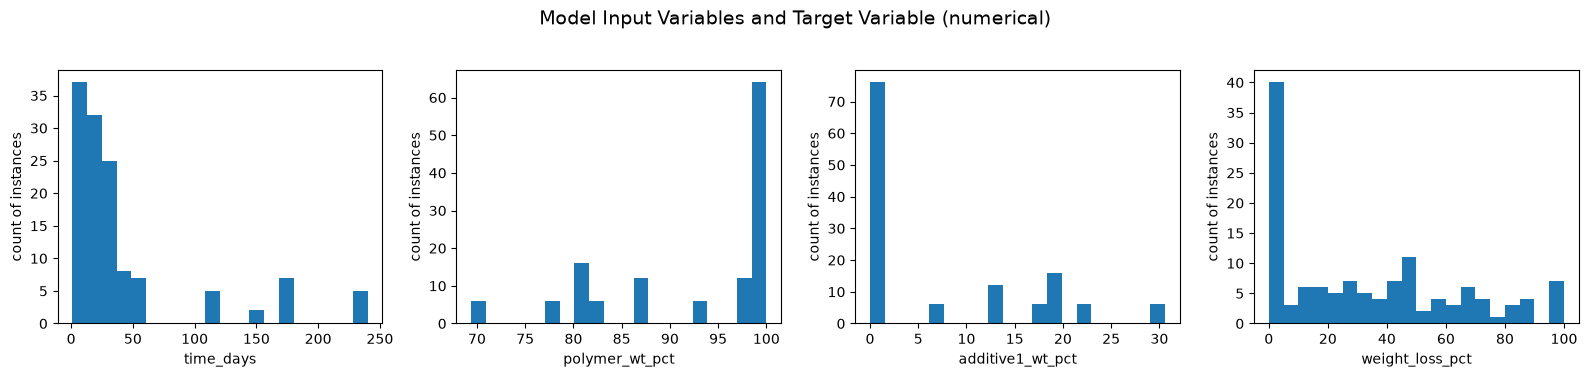

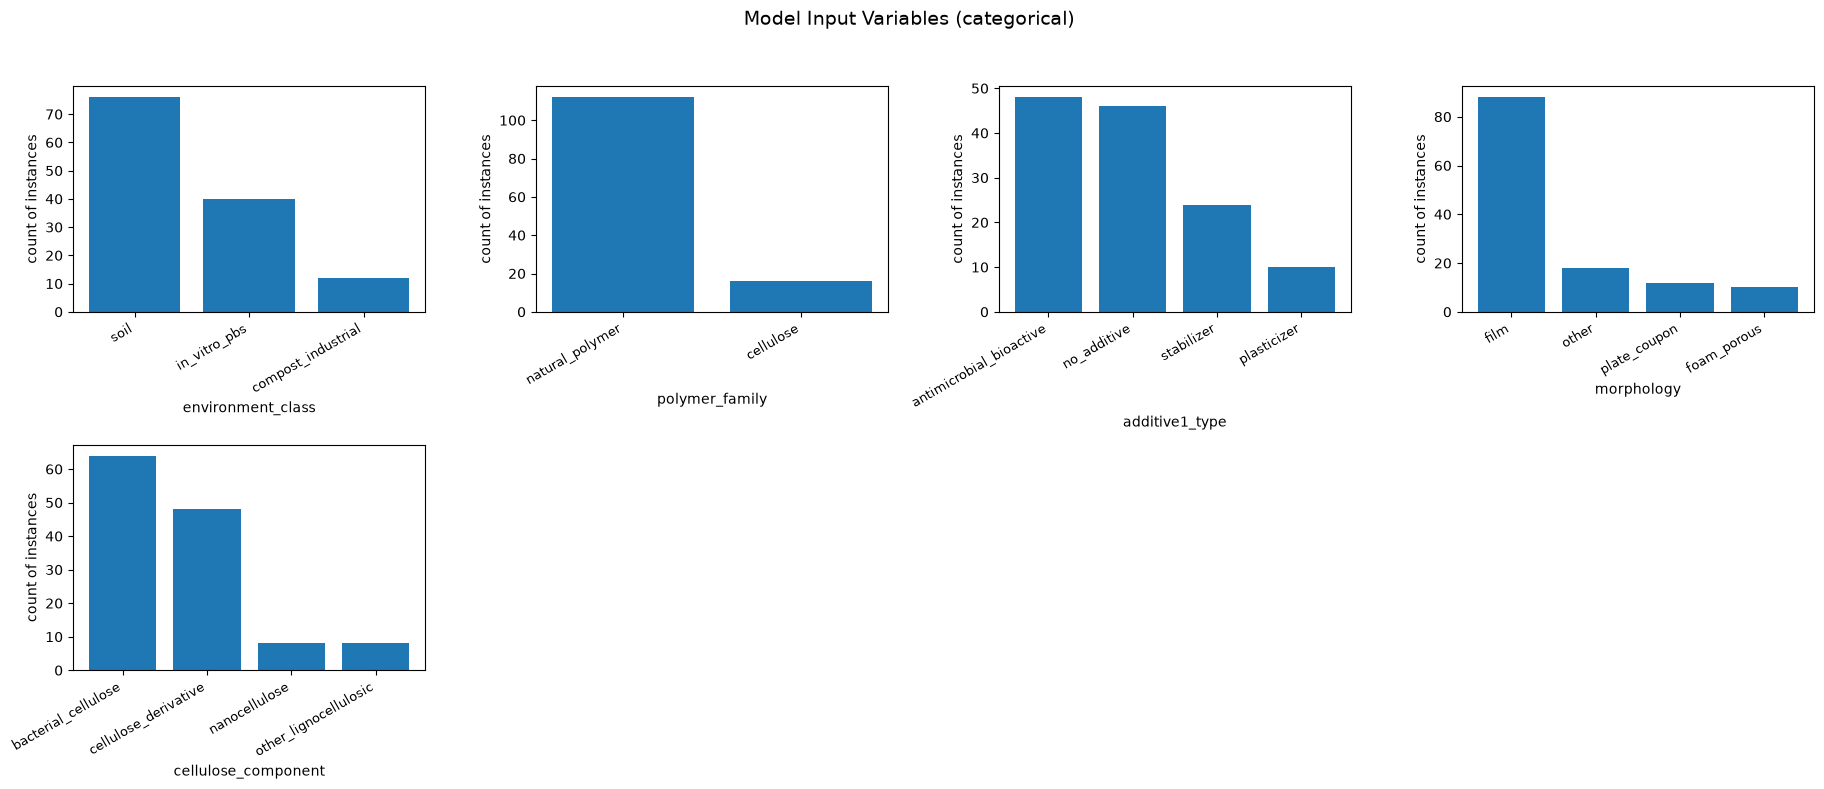

In [442]:
def plot_feature_distributions(
    df: pd.DataFrame,
    numerical_cols,
    categorical_cols,
    title_numeric="Model Input Variables and Target Variable (numerical)",
    title_categorical="Model Input Variables (categorical)",
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,   # cap bars for very high-cardinality cats
):
    # ---------- helper to grid-plot ----------
    def _grid_dims(n, max_cols):
        cols = min(max_cols, max(1, n))
        rows = int(math.ceil(n / cols))
        return rows, cols

    # ---------- NUMERICAL ----------
    if len(numerical_cols) > 0:
        n = len(numerical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.0*cols, 3.8*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_numeric, fontsize=14, y=0.98)

        for i, col in enumerate(numerical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            x = df[col].dropna().values
            ax.hist(x, bins=bins)
            #ax.set_title(str(col), fontsize=10)
            ax.set_ylabel("count of instances")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

    # ---------- CATEGORICAL ----------
    if len(categorical_cols) > 0:
        n = len(categorical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.6*cols, 4.0*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_categorical, fontsize=14, y=0.98)

        for i, col in enumerate(categorical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            vc = (df[col].astype(str).replace("nan", np.nan)
                                 .value_counts(dropna=False)
                                 .head(top_k_categories))
            ax.bar(range(len(vc)), vc.values)
            ax.set_xticks(range(len(vc)))
            ax.set_xticklabels(vc.index.astype(str), rotation=30, ha="right", fontsize=9)
            #ax.set_title(str(col), fontsize=10)
            ax.set_ylabel("count of instances")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()



plot_feature_distributions(
    df_final,
    numerical_cols_lst,
    categorical_cols_lst,
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,
)

## Correlation matrix of numerical features

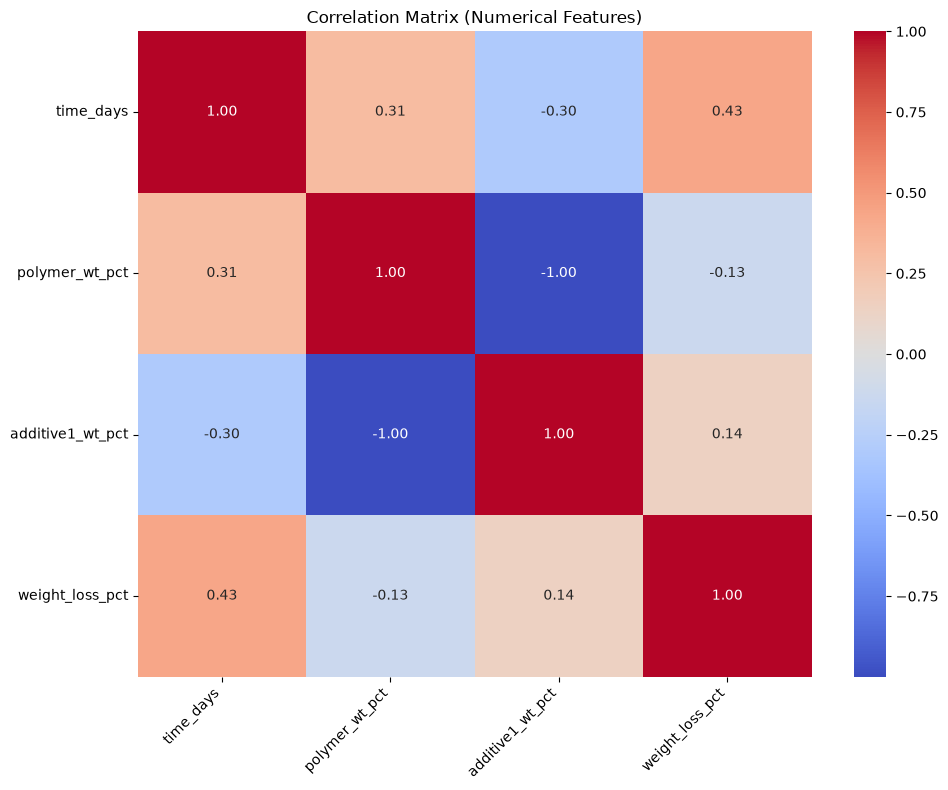

In [444]:
numerical_df = df_final[numerical_cols_lst]

# Compute correlation matrix
corr_matrix = numerical_df.corr() 

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix (Numerical Features)")
plt.xticks(rotation=45, ha="right") 
plt.yticks(rotation=0) 

plt.tight_layout()
# plt.savefig("correlation.tiff", format="tiff", dpi=600, bbox_inches="tight")
plt.show()

## Exclude additive type 1 %

In [446]:
df_final.drop(columns=['additive1_wt_pct'], inplace=True)

## Train - test splitting

In [450]:
# Separate features and target
X = df_final.drop(columns=[target]) 
y = df_final[target]

In [453]:
split_method = 'kennard_stone'    # 'random' | 'kennard_stone' 
test_size = 0.2

def encode_for_distance(X):
    # one-hot + standardise
    Xe = pd.get_dummies(X, columns=[c for c in categorical_cols_lst if c in X.columns], dtype=float)
    return StandardScaler().fit_transform(Xe)

def kennard_stone_split(Z, n_train, y=None):
    D = cdist(Z, Z)
    if y is not None:     
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        Dy = cdist(y, y)
        D = D / D.max() + Dy / Dy.max()
    i, j = np.unravel_index(np.argmax(D), D.shape)          # the two most distant samples
    selected = [i, j]
    remaining = [k for k in range(len(Z)) if k not in selected]
    while len(selected) < n_train:                           # add the sample farthest from the selected set
        dmin = D[np.ix_(remaining, selected)].min(axis=1)
        k = remaining[int(np.argmax(dmin))]
        selected.append(k)
        remaining.remove(k)
    return np.sort(selected), np.sort(remaining)

def split_data(X, y, method='kennard_stone', n_test=3, seed=42):
    if method == 'random':
        return train_test_split(X, y, test_size=n_test, random_state=seed)
    n_train = len(X) - n_test
    Z = encode_for_distance(X)
    tr, te = kennard_stone_split(Z, n_train, y=(y.values if method == 'spxy' else None))
    return X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]

heldout_idx = heldout_idx.intersection(X.index)
n_test_total = int(math.ceil(test_size * len(X)))
n_test_split = max(n_test_total - len(heldout_idx), 1)     # rows still to be chosen by the split algorithm

def make_split(method, seed=42):
    # split the pool (all rows except the held-out instances), then add the held-out instances to the test set
    Xp, yp = X.drop(index=heldout_idx), y.drop(index=heldout_idx)
    Xtr, Xte, ytr, yte = split_data(Xp, yp, method, n_test_split, seed)
    return Xtr, pd.concat([Xte, X.loc[heldout_idx]]), ytr, pd.concat([yte, y.loc[heldout_idx]])

X_train, X_test, y_train, y_test = make_split(split_method)
test_origin = pd.Series(np.where(X_test.index.isin(heldout_idx), 'held-out instance', 'split'), index=X_test.index)

print('Split method:', split_method)
print('Train set size:', X_train.shape, '\n Test set size', X_test.shape)
print('Train studies:', groups_all.loc[X_train.index].value_counts().sort_index().to_dict())
print('Test studies: ', groups_all.loc[X_test.index].value_counts().sort_index().to_dict())

Split method: kennard_stone
Train set size: (102, 7) 
 Test set size (26, 7)
Train studies: {'s002': 6, 's005': 18, 's006': 8, 's008': 8, 's010': 48, 's012': 10, 's014': 4}
Test studies:  {'s002': 4, 's005': 6, 's006': 4, 's012': 10, 's014': 2}


## FAMD for outlier detection - only on the Train set (if applied)

In [456]:
# Fit FAMD with a reasonably high number of components
famd = FAMD(n_components=20, n_iter=10, random_state=42).fit(X_train)

eigenvalues = famd.eigenvalues_
explained_inertia = eigenvalues / eigenvalues.sum()
cumulative_inertia = np.cumsum(explained_inertia)

famd.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,3.693,26.38%,26.38%
1,2.965,21.18%,47.56%
2,2.180,15.57%,63.13%
3,1.761,12.58%,75.71%
4,1.335,9.54%,85.25%
5,0.561,4.01%,89.26%
6,0.494,3.53%,92.79%
7,0.407,2.90%,95.69%
8,0.292,2.09%,97.78%


In [458]:
# Initial FAMD for outlier detection
n_components_initial = 11
famd2 = FAMD(n_components=n_components_initial, random_state=42)
X_train_famd = famd2.fit_transform(X_train)

X_train_famd.info()

<class 'pandas.DataFrame'>
Index: 102 entries, 0 to 137
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       102 non-null    float64
 1   1       102 non-null    float64
 2   2       102 non-null    float64
 3   3       102 non-null    float64
 4   4       102 non-null    float64
 5   5       102 non-null    float64
 6   6       102 non-null    float64
 7   7       102 non-null    float64
 8   8       102 non-null    float64
 9   9       102 non-null    float64
 10  10      102 non-null    float64
dtypes: float64(11)
memory usage: 9.6 KB


In [460]:
X_train_famd_df = X_train_famd.copy()
X_train_famd_df.columns = [f'Comp{i+1}' for i in range(X_train_famd_df.shape[1])]

X_train_famd_df.tail()

,Comp1,Comp2,Comp3,Comp4,Comp5,Comp6,Comp7,Comp8,Comp9,Comp10,Comp11
119,3.086832,-0.092382,-0.117834,0.073382,5.620165,-1.042495,-0.382521,0.696515,0.340097,-0.756247,0.014424
132,0.404540,1.179017,-0.347619,-0.937055,-0.944793,-1.714887,2.466412,-0.253647,-0.337269,-0.089949,-0.035965
135,0.426821,1.172377,-0.356695,-0.937339,-0.928159,-1.709143,2.461044,-0.223829,-0.326625,-0.124154,-0.033767
136,0.449102,1.165737,-0.365771,-0.937622,-0.911524,-1.703399,2.455676,-0.194011,-0.315982,-0.158359,-0.031569
137,0.471383,1.159098,-0.374847,-0.937906,-0.894890,-1.697654,2.450309,-0.164194,-0.305338,-0.192564,-0.029371


## Outlier detection with IQR

**Test = 1:** No exclusion
**Test = 2:** +-10 IQR   **Test = 3:** +-7 IQR  

In [463]:
test = 1

# Detect outliers using IQR
def detect_iqr_outliers(df,alpha):
    outlier_indices = set()
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - alpha * IQR
        upper_bound = Q3 + alpha * IQR
        outliers_col = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index
        outlier_indices.update(outliers_col)
    return list(outlier_indices)

# Drop outliers
if test == 2:
    alpha = 10
    outlier_idx_train = detect_iqr_outliers(X_train_famd_df, alpha)
    X_train_clean = X_train.drop(index=outlier_idx_train)
    y_train_clean = y_train.drop(index=outlier_idx_train)
    print("IQR outlier detection APPLIED with ±2")

elif test == 3:
    alpha = 7
    outlier_idx_train = detect_iqr_outliers(X_train_famd_df, alpha)
    X_train_clean = X_train.drop(index=outlier_idx_train)
    y_train_clean = y_train.drop(index=outlier_idx_train)
    print("IQR outlier detection APPLIED with ±",alpha)

else:
    df_clean = df_final.copy()
    X_train_clean = X_train
    y_train_clean = y_train
    print("IQR outlier detection SKIPPED")

print(f"Original data shape: {X_train.shape}")
print(f"Cleaned data shape: {X_train_clean.shape}")

IQR outlier detection SKIPPED
Original data shape: (102, 7)
Cleaned data shape: (102, 7)


In [465]:
X_train_clean.tail()

,time_days,environment_class,polymer_family,polymer_wt_pct,additive1_type,morphology,cellulose_component
119,240.0,soil,natural_polymer,100.0,no_additive,plate_coupon,bacterial_cellulose
132,1.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,other,bacterial_cellulose
135,4.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,other,bacterial_cellulose
136,7.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,other,bacterial_cellulose
137,10.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,other,bacterial_cellulose


## One-hot encoding

In [468]:
X_train = X_train_clean.copy()

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop=None)
ohe.fit(X_train[categorical_cols_lst])

# Transform
X_train_ohe = ohe.transform(X_train[categorical_cols_lst])
X_test_ohe = ohe.transform(X_test[categorical_cols_lst])

# Convert to DataFrame with proper column names
ohe_columns = ohe.get_feature_names_out(categorical_cols_lst)
X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=ohe_columns, index=X_train.index)
X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=ohe_columns, index=X_test.index)

In [470]:
# combine
X_train_final = pd.concat([X_train.drop(columns=categorical_cols_lst), X_train_ohe_df], axis=1)
X_test_final = pd.concat([X_test.drop(columns=categorical_cols_lst), X_test_ohe_df], axis=1)

print(f"X_train_final shape: {X_train_final.shape}")
print(f"X_test_final shape: {X_test_final.shape}")

X_train_final shape: (102, 19)
X_test_final shape: (26, 19)


## Feature importance in the train set

In [473]:
def corr_ratio(cat_s, num_s):
    # correlation ratio eta (0-1)
    m = num_s.mean(); sst = ((num_s - m) ** 2).sum()
    ssb = sum(len(v) * (v.mean() - m) ** 2 for _, v in num_s.groupby(cat_s))
    return float(np.sqrt(ssb / sst)) if sst > 0 else 0.0

cat_f = [c for c in X_train.columns if c in categorical_cols_lst]
num_f = [c for c in X_train.columns if c not in cat_f]
for c in cat_f:
    for n_ in num_f:
        print(f'eta({c}, {n_}) = {corr_ratio(X_train[c], X_train[n_]):.2f}')
print('\nrelation with the target (train rows):')
for c in cat_f:
    print(f'  eta({c}, target) = {corr_ratio(X_train[c], y_train):.2f}')
for n_ in num_f:
    print(f'  |Pearson r|({n_}, target) = {abs(np.corrcoef(X_train[n_], y_train)[0, 1]):.2f}')

eta(environment_class, time_days) = 0.37
eta(environment_class, polymer_wt_pct) = 0.36
eta(polymer_family, time_days) = 0.66
eta(polymer_family, polymer_wt_pct) = 0.35
eta(additive1_type, time_days) = 0.57
eta(additive1_type, polymer_wt_pct) = 0.82
eta(morphology, time_days) = 0.64
eta(morphology, polymer_wt_pct) = 0.47
eta(cellulose_component, time_days) = 0.47
eta(cellulose_component, polymer_wt_pct) = 0.64

relation with the target (train rows):
  eta(environment_class, target) = 0.54
  eta(polymer_family, target) = 0.17
  eta(additive1_type, target) = 0.60
  eta(morphology, target) = 0.30
  eta(cellulose_component, target) = 0.43
  |Pearson r|(time_days, target) = 0.42
  |Pearson r|(polymer_wt_pct, target) = 0.20


## Remove features "polymer_family" , "cellulose_component" and "morphology"

In [476]:
fam_cols1 = [c for c in X_train_final.columns if c.startswith("polymer_family") or c.startswith("cellulose_component") or c.startswith("morphology")]
X_train_final = X_train_final.drop(columns=fam_cols1)
X_test_final  = X_test_final.drop(columns=fam_cols1)

## RF and XGBoost regression

In [479]:
# XGBoost
xgb = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="rmse",
    n_jobs=-1
)

xgb.fit(X_train_final, y_train_clean)

# Predictions
y_train_pred_xgb = xgb.predict(X_train_final)
y_test_pred_xgb = xgb.predict(X_test_final)


# Random Forest
rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_final, y_train_clean)

# Predictions
y_train_pred_rf = rf.predict(X_train_final)
y_test_pred_rf = rf.predict(X_test_final)

In [481]:
def compute_metrics(y_true, y_pred):
    return {
        'R^2': r2_score(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred)
    }

metrics = []

# XGBoost
train_xgb = compute_metrics(y_train_clean, y_train_pred_xgb)
test_xgb = compute_metrics(y_test, y_test_pred_xgb)

metrics.append(['XGBoost', 'Train', train_xgb['R^2'], train_xgb['RMSE'], train_xgb['MAE']])
metrics.append(['XGBoost', 'Test',  test_xgb['R^2'],  test_xgb['RMSE'],  test_xgb['MAE']])

# Random Forest
train_rf = compute_metrics(y_train_clean, y_train_pred_rf)
test_rf = compute_metrics(y_test, y_test_pred_rf)

metrics.append(['Random Forest', 'Train', train_rf['R^2'], train_rf['RMSE'], train_rf['MAE']])
metrics.append(['Random Forest', 'Test',  test_rf['R^2'],  test_rf['RMSE'],  test_rf['MAE']])

In [483]:
metrics_df = pd.DataFrame(
    metrics,
    columns=['Model', 'Dataset', 'R^2', 'RMSE', 'MAE']
)

print(metrics_df)

           Model Dataset       R^2       RMSE       MAE
0        XGBoost   Train  0.945993   7.280514  3.406999
1        XGBoost    Test  0.817212  11.759105  6.762371
2  Random Forest   Train  0.936612   7.887508  4.596490
3  Random Forest    Test  0.804632  12.157020  7.350102


## Grid search - RF

In [64]:
# Define the parameter grid
param_grid = {
    "n_estimators":     [300, 500],
    "max_depth":        [6, 8],
    "min_samples_leaf": [1, 3],
    "max_features":     [0.5, 1.0],
}

# Kfold
groups_train = groups_all.loc[X_train_final.index]
n_splits = int(min(4, groups_train.nunique()))
folds = 5
n_repeats = 5
cv = RepeatedKFold(n_splits=folds, n_repeats=n_repeats, random_state=42)


# Initialize the Grid Search with Random Forest
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=cv, scoring='r2', n_jobs=1, verbose=2)

# Fit
grid_search.fit(X_train_final, y_train_clean)

# Extract the best parameters and best score
best_params = grid_search.best_params_
best_score = grid_search.best_score_

# Print
print(f"Best parameters found: {best_params}")
print(f"Best R^2 score from Grid Search (CV): {best_score}")

# Use the best estimator
best_rf = grid_search.best_estimator_

# Predictions
y_train_pred_grid = best_rf.predict(X_train_final)
y_test_pred_grid = best_rf.predict(X_test_final)

# Metrics
r2_train_grid = r2_score(y_train_clean, y_train_pred_grid)
r2_test_grid = r2_score(y_test, y_test_pred_grid)

# Pearson r
pearson_r_train, _ = pearsonr(y_train_clean, y_train_pred_grid)
pearson_r_test, _ = pearsonr(y_test, y_test_pred_grid)

# Cross-Validation R^2 Score with the best model
cv_scores_r2_grid = cross_val_score(best_rf, X_train_final, y_train_clean, cv=cv, scoring='r2')
mean_cv_r2_grid = np.mean(cv_scores_r2_grid)
std_cv_r2_grid = np.std(cv_scores_r2_grid)

# Print the R^2 scores
summary_df = pd.DataFrame({
    'Metric': ['Train R^2', 'Test R^2', 'CV Mean R^2', 'CV SD R^2', 'Train Pearson r', 'Test Pearson r'],
    'RF (Tuned)': [
        r2_train_grid,
        r2_test_grid,
        mean_cv_r2_grid,
        std_cv_r2_grid,
        pearson_r_train,
        pearson_r_test
    ]
})

print(summary_df)

Fitting 25 folds for each of 16 candidates, totalling 400 fits
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   1.1s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.8s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.7s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.6s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.7s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.7s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.8s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.7s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300; total time=   0.9s
[CV] END max_depth=6, max_features=0.5, min_samples_leaf=1, n_es

In [66]:
study = df_weight.loc[X_train_final.index, 'study_id'].reset_index(drop=True)
sample = df_weight.loc[X_train_final.index, 'sample_id'].reset_index(drop=True)

# studies with more than one sample (instance)
n_samples = sample.groupby(study).nunique()
multi_studies = n_samples[n_samples > 1].index
print("held-out candidates:", list(multi_studies))
print("never held out (single-sample):", list(n_samples[n_samples == 1].index))

class MultiSampleLOIO:
    """Leave-one-instance-out, only for instances whose study has >1 sample.
       Single-sample studies are always in the training part."""
    def __init__(self, study, sample):
        self.study, self.sample = np.asarray(study), np.asarray(sample)
        n = pd.Series(self.sample).groupby(self.study).nunique()
        self.multi = set(n[n > 1].index)
        self.instances = [s for s in pd.unique(self.sample)
                          if self.study[self.sample == s][0] in self.multi]
    def get_n_splits(self, X=None, y=None, groups=None):
        return len(self.instances)
    def split(self, X=None, y=None, groups=None):
        for inst in self.instances:
            te = np.where(self.sample == inst)[0]
            tr = np.where(self.sample != inst)[0]
            yield tr, te

cv_loio = MultiSampleLOIO(study, sample)

# pooled out-of-fold predictions on the held-out instances only
Xr, yr = X_train_final.reset_index(drop=True), np.asarray(y_train_clean)
mask = np.zeros(len(yr), bool); oof = np.full(len(yr), np.nan)
for tr, te in cv_loio.split():
    m = clone(best_rf).fit(Xr.iloc[tr], yr[tr])
    oof[te] = np.clip(m.predict(Xr.iloc[te]), 0, 100); mask[te] = True

print(f"LOIO (multi-sample studies only): n={mask.sum()}  "
      f"R2={r2_score(yr[mask], oof[mask]):.3f}  RMSE={root_mean_squared_error(yr[mask], oof[mask]):.2f}  "
      f"MAE={mean_absolute_error(yr[mask], oof[mask]):.2f}  r={pearsonr(yr[mask], oof[mask])[0]:.3f}")

held-out candidates: ['s002', 's005', 's006', 's008', 's010', 's012']
never held out (single-sample): ['s014']
LOIO (multi-sample studies only): n=98  R2=0.791  RMSE=14.52  MAE=10.62  r=0.890


## Plot results

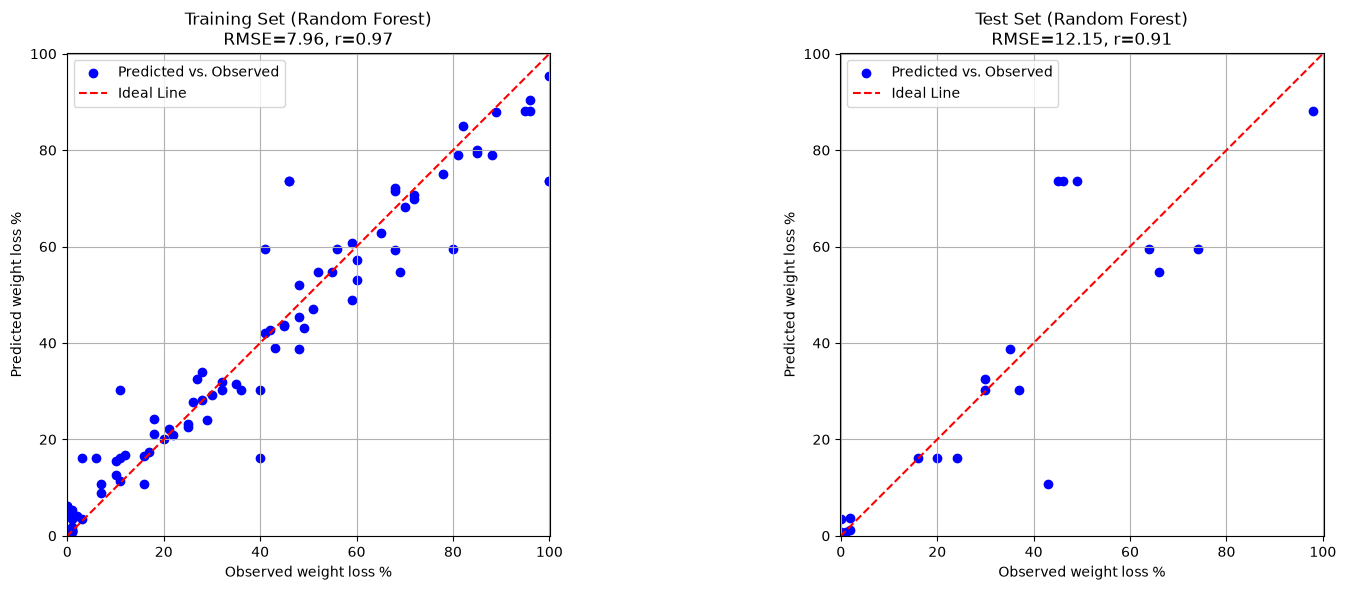

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6)) 

# common axis limits
all_vals = np.concatenate([y_train_clean, y_test, y_train_pred_grid, y_test_pred_grid])
lo, hi = all_vals.min() - 0.15, all_vals.max() + 0.15

# Plot Training Set
axes[0].scatter(y_train_clean, y_train_pred_grid, color='blue', label='Predicted vs. Observed')
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[0].set_xlabel('Observed weight loss %')
axes[0].set_ylabel('Predicted weight loss %')
axes[0].set_title(f'Training Set (Random Forest)\nRMSE={root_mean_squared_error(y_train_clean, y_train_pred_grid):.2f}, '
                  f'r={pearsonr(y_train_clean, y_train_pred_grid)[0]:.2f}')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi); axes[0].set_aspect('equal')
axes[0].legend()
axes[0].grid(True)

# Plot Test Set
# axes[1].scatter(y_test, y_test_pred_grid4, color='green', label='Predicted vs. Observed')
held_mask = (test_origin.to_numpy() == 'held-out instance')     # test_origin is indexed like X_test
y_te = np.asarray(y_test)

axes[1].scatter(y_test, y_test_pred_grid, color='blue', label='Predicted vs. Observed')
axes[1].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[1].set_xlabel('Observed weight loss %')
axes[1].set_ylabel('Predicted weight loss %')
axes[1].set_title(f'Test Set (Random Forest)\nRMSE={root_mean_squared_error(y_test, y_test_pred_grid):.2f}, '
                  f'r={pearsonr(y_test, y_test_pred_grid)[0]:.2f}')
axes[1].set_xlim(lo, hi); axes[1].set_ylim(lo, hi); axes[1].set_aspect('equal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("weight_cell_rf_tuned.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Plot RMSE w.r.t No of trees

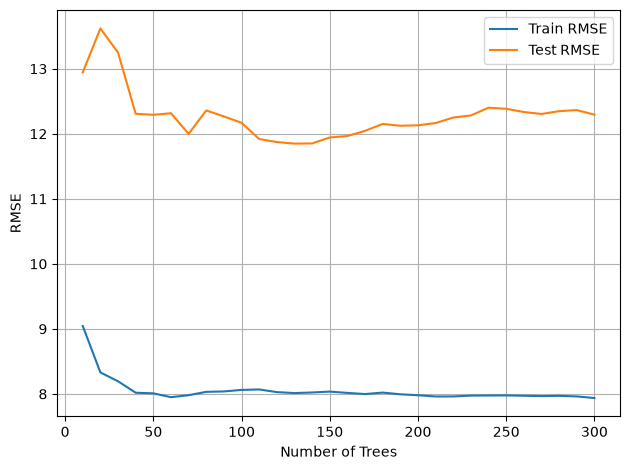

In [70]:
train_rmse = []
test_rmse = []

n_estimators_range = range(10, 301, 10)

for n in n_estimators_range:
    rf = RandomForestRegressor(
        n_estimators=n,
        max_depth=best_params['max_depth'],
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_final, y_train_clean)

    y_train_pred = rf.predict(X_train_final)
    y_test_pred = rf.predict(X_test_final)

    train_rmse.append(root_mean_squared_error(y_train_clean, y_train_pred))
    test_rmse.append(root_mean_squared_error(y_test, y_test_pred))

plt.figure()
plt.plot(n_estimators_range, train_rmse, label="Train RMSE")
plt.plot(n_estimators_range, test_rmse, label="Test RMSE")
plt.xlabel("Number of Trees")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("RF_RMSE.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Feature importance

In [72]:
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_final)     # array shape: (n_samples, n_features)
base_value = explainer.expected_value

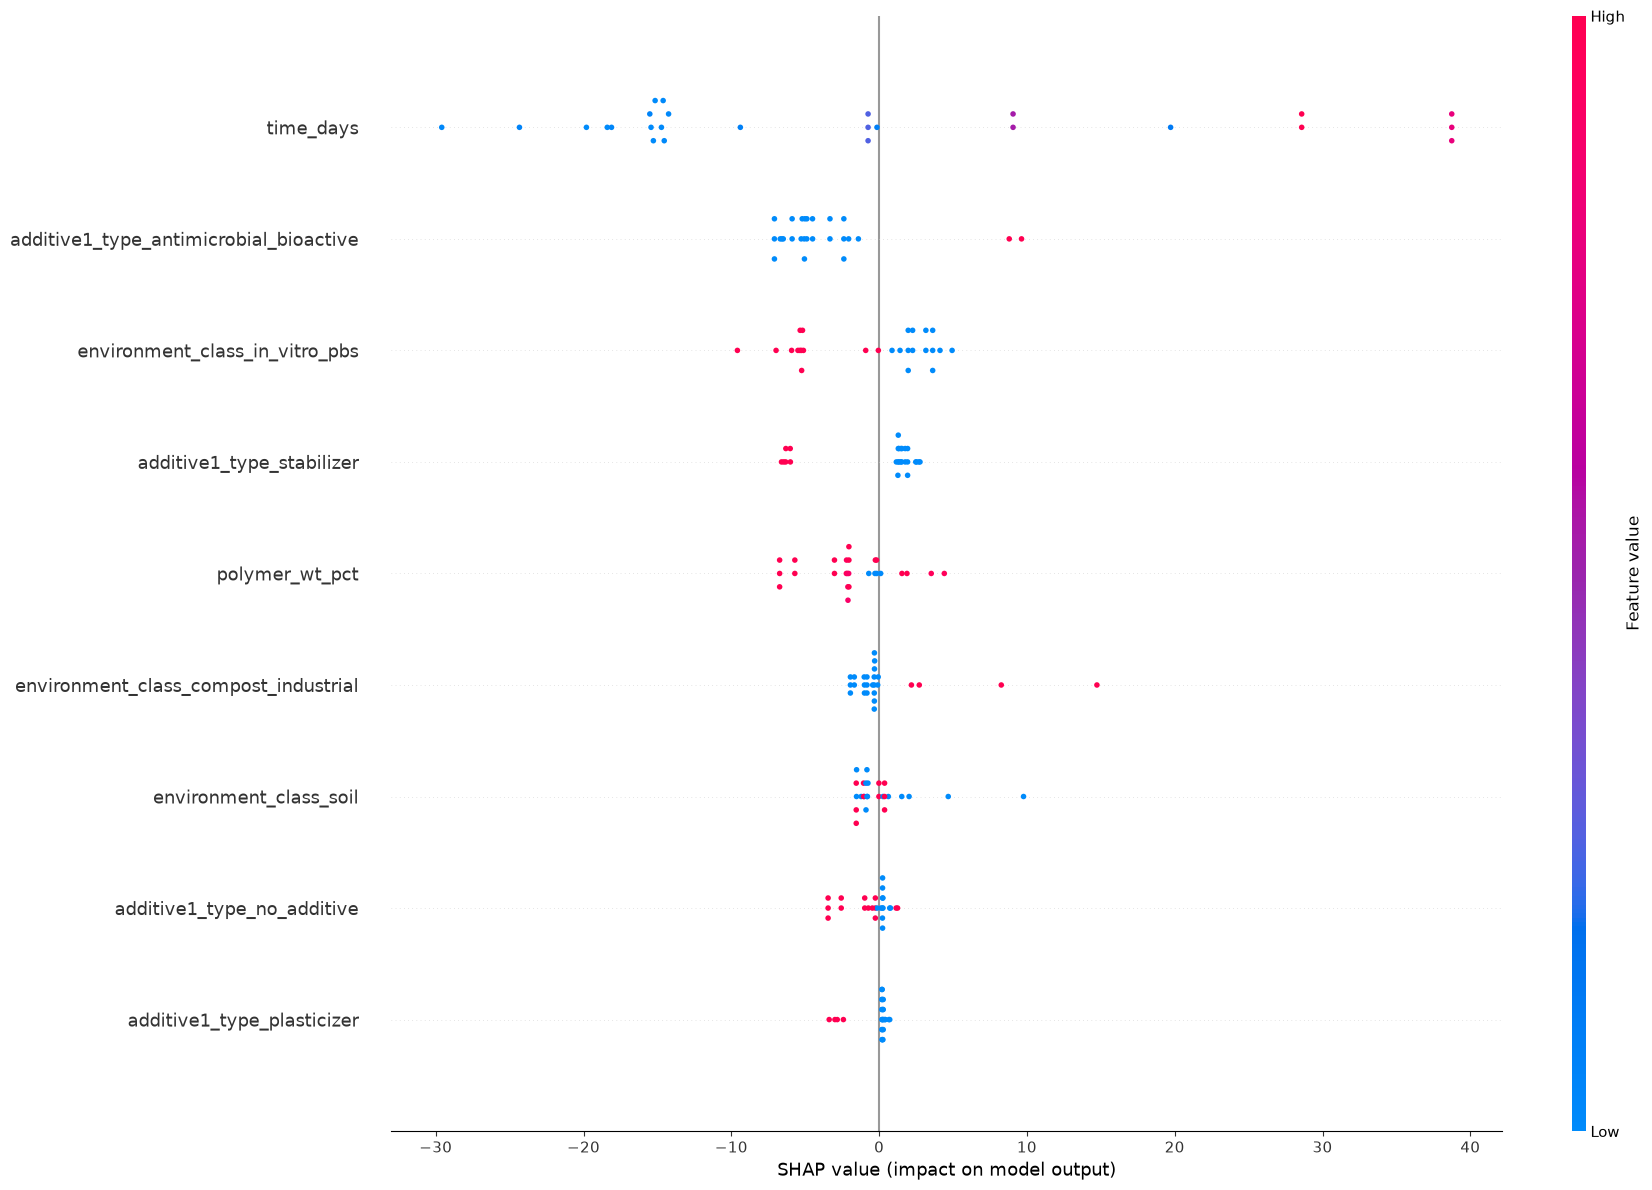

In [74]:
shap.summary_plot(
    shap_values,
    X_test_final,
#    max_display=10,        # <-- top 10 features only
    show=False,
    plot_size=(18, 12)
)

plt.tight_layout()
plt.savefig("RF_shap.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Grid search - XGBoost

In [102]:
# +1 for time_days, 0 for every other column, in the column order of X_train_final
mono = [1 if c == 'time_days' else 0 for c in X_train_final.columns]

xgb = XGBRegressor(random_state=42, monotone_constraints=tuple(mono))

# Define the parameter grid
param_grid = {
     'n_estimators': [800],
    'learning_rate': [0.01, 0.05],
    'max_depth': [4], # , 6],
    'subsample': [0.7], # 0.8],
    'colsample_bytree': [0.7, 0.8],
}

# Initialize the Grid Search with Random Forest
grid_search2 = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=cv, scoring='r2', n_jobs=1, verbose=2)

# Fit
grid_search2.fit(X_train_final, y_train_clean)

# Extract the best parameters
best_params2 = grid_search2.best_params_
best_score2 = grid_search2.best_score_

# Print
print(f"Best parameters found: {best_params2}")
print(f"Best R^2 score from Grid Search (CV): {best_score2}")

# Use the best estimator
best_xgb = grid_search2.best_estimator_

# predictions
y_train_pred_grid2 = best_xgb.predict(X_train_final)
y_test_pred_grid2 = best_xgb.predict(X_test_final)

# Metrics
r2_train_grid2 = r2_score(y_train_clean, y_train_pred_grid2)
r2_test_grid2 = r2_score(y_test, y_test_pred_grid2)

# Pearson r
pearson_r_train2, _ = pearsonr(y_train_clean, y_train_pred_grid2)
pearson_r_test2, _ = pearsonr(y_test, y_test_pred_grid2)

# Cross-Validation R^2 Score with the best model
cv_scores_r2_grid2 = cross_val_score(best_xgb, X_train_final, y_train_clean, cv=cv, scoring='r2')
mean_cv_r2_grid2 = np.mean(cv_scores_r2_grid2)
std_cv_r2_grid2 = np.std(cv_scores_r2_grid2)

# Print the R^2 scores
summary_df2 = pd.DataFrame({
    'Metric': ['Train R^2', 'Test R^2', 'CV Mean R^2', 'CV SD R^2', 'Train Pearson r', 'Test Pearson r'],
    'XGBoost (Tuned)': [
        r2_train_grid2,
        r2_test_grid2,
        mean_cv_r2_grid2,
        std_cv_r2_grid2,
        pearson_r_train2,
        pearson_r_test2
    ]
})

print(summary_df2)

Fitting 25 folds for each of 4 candidates, totalling 100 fits
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.6s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.6s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.7s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.6s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.5s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.7s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.8s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=4, n_estimators=800, subsample=0.7; total time=   2.8s
[CV] END c

In [104]:
for tr, te in cv_loio.split():
    m = clone(best_xgb).fit(Xr.iloc[tr], yr[tr])
    oof[te] = np.clip(m.predict(Xr.iloc[te]), 0, 100); mask[te] = True

print(f"LOIO (multi-sample studies only - XGBoost): n={mask.sum()}  "
      f"R2={r2_score(yr[mask], oof[mask]):.3f}  RMSE={root_mean_squared_error(yr[mask], oof[mask]):.2f}  "
      f"MAE={mean_absolute_error(yr[mask], oof[mask]):.2f}  r={pearsonr(yr[mask], oof[mask])[0]:.3f}")

LOIO (multi-sample studies only - XGBoost): n=98  R2=0.784  RMSE=14.79  MAE=10.79  r=0.887


## Plot results

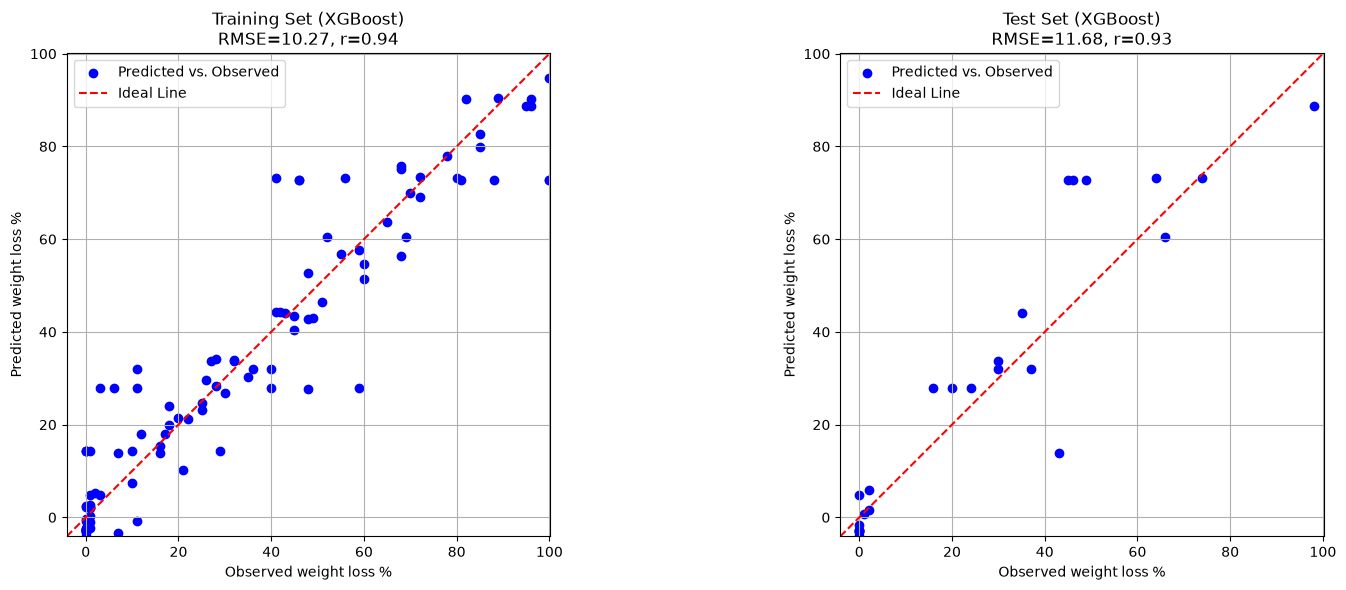

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))  # width doubled for 2 plots

# common axis limits so both panels are comparable
all_vals = np.concatenate([y_train_clean, y_test, y_train_pred_grid2, y_test_pred_grid2])
lo, hi = all_vals.min() - 0.15, all_vals.max() + 0.15

# Plot Training Set
axes[0].scatter(y_train_clean, y_train_pred_grid2, color='blue', label='Predicted vs. Observed')
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[0].set_xlabel('Observed weight loss %')
axes[0].set_ylabel('Predicted weight loss %')
axes[0].set_title(f'Training Set (XGBoost)\nRMSE={root_mean_squared_error(y_train_clean, y_train_pred_grid2):.2f}, '
                  f'r={pearsonr(y_train_clean, y_train_pred_grid2)[0]:.2f}')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi); axes[0].set_aspect('equal')
axes[0].legend()
axes[0].grid(True)

# Plot Test Set
# axes[1].scatter(y_test, y_test_pred_grid4, color='green', label='Predicted vs. Observed')
held_mask = (test_origin.to_numpy() == 'held-out instance')     # test_origin is indexed like X_test
y_te = np.asarray(y_test)

# replace the test-set scatter (axes[1]) in your plotting cell
axes[1].scatter(y_test, y_test_pred_grid2, color='blue', label='Predicted vs. Observed')
axes[1].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[1].set_xlabel('Observed weight loss %')
axes[1].set_ylabel('Predicted weight loss %')
axes[1].set_title(f'Test Set (XGBoost)\nRMSE={root_mean_squared_error(y_test, y_test_pred_grid2):.2f}, '
                  f'r={pearsonr(y_test, y_test_pred_grid2)[0]:.2f}')
axes[1].set_xlim(lo, hi); axes[1].set_ylim(lo, hi); axes[1].set_aspect('equal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("weight_cell_xg_tuned.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Loss plot

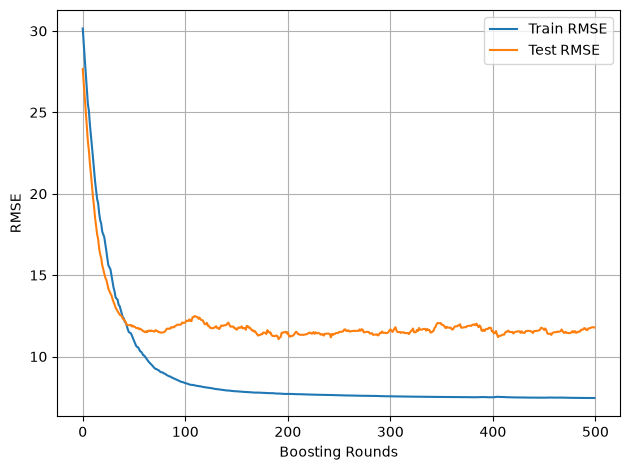

In [108]:
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=best_params2['max_depth'],
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric=["rmse"],
    random_state=42
)

model.fit(
    X_train_final, y_train_clean,
    eval_set=[(X_train_final, y_train_clean), (X_test_final, y_test)],
    verbose=False
)

results = model.evals_result()

epochs = len(results['validation_0']['rmse'])

plt.figure()
plt.plot(range(epochs), results['validation_0']['rmse'], label="Train RMSE")
plt.plot(range(epochs), results['validation_1']['rmse'], label="Test RMSE")
plt.xlabel("Boosting Rounds")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("XGB_loss.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Feature importance

In [111]:
explainer2 = shap.TreeExplainer(best_xgb)
shap_values2 = explainer2.shap_values(X_test_final)     # array shape: (n_samples, n_features)
base_value2 = explainer2.expected_value

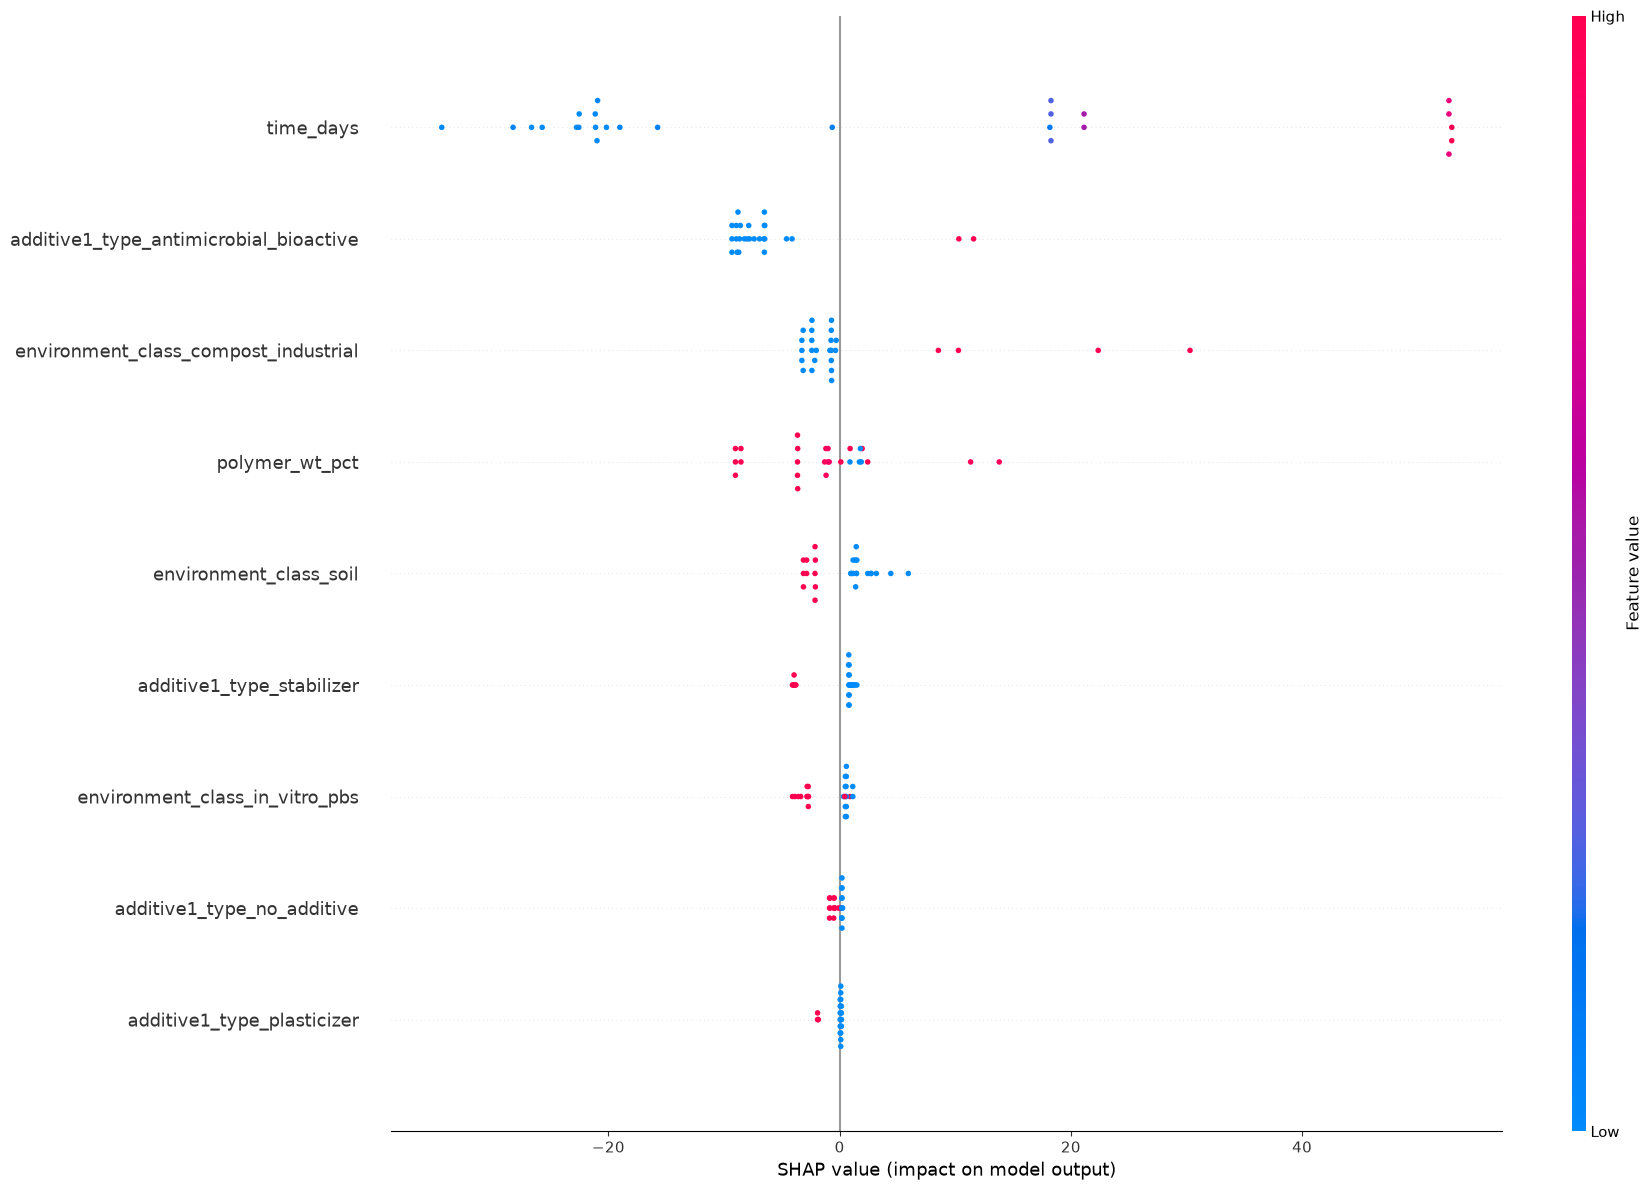

In [113]:
shap.summary_plot(
    shap_values2,
    X_test_final,
 #   max_display=10,        # <-- top 10 features only
    show=False,
    plot_size=(18, 12)
)

plt.tight_layout()
plt.savefig("XGB_shap.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Validation check on unseen data (excl. full instances)

In [116]:
# transform validation set

X_val = df_val.drop(columns=[target,'study_id','sample_id'])
X_val_ohe = ohe.transform(X_val[categorical_cols_lst])
X_val_ohe_df = pd.DataFrame(X_val_ohe, columns=ohe_columns, index=X_val.index)
X_val_final = pd.concat([X_val.drop(columns=categorical_cols_lst), X_val_ohe_df], axis=1)
# Align validation features with the exact columns used during training
X_val_final = X_val_final.reindex(columns=X_train_final.columns, fill_value=0)

In [118]:
df_val.columns

Index(['time_days', 'weight_loss_pct', 'study_id', 'sample_id',
       'environment_class', 'polymer_family', 'polymer_wt_pct',
       'additive1_type', 'additive1_wt_pct', 'morphology',
       'cellulose_component'],
      dtype='str')

In [120]:
cols = X_val_final.columns.tolist()
first_col = cols.pop(0)

# Insert it at index 2 (third position)
cols.insert(2, first_col)
# X_val_final = X_val_final[cols]
y_val = df_val[target]

# RF
y_val_pred_rf = best_rf.predict(X_val_final)
r2_val_rf = r2_score(y_val, y_val_pred_rf)
pearson_r_val_rf, _ = pearsonr(y_val, y_val_pred_rf)
print(f'R^2 score on unseen set (RF): {r2_val_rf}')
print(f'Pearson r on unseen set (RF): {pearson_r_val_rf}')

# XGBoost
y_val_pred_xg = best_xgb.predict(X_val_final)
r2_val_xg = r2_score(y_val, y_val_pred_xg)
pearson_r_val_xg, _ = pearsonr(y_val, y_val_pred_xg)
print(f'R^2 score on unseen set (xgb): {r2_val_xg}')
print(f'Pearson r on unseen set (xgb): {pearson_r_val_xg}')

R^2 score on unseen set (RF): 0.5952544747830651
Pearson r on unseen set (RF): 0.8149328873929531
R^2 score on unseen set (xgb): 0.6453859314141746
Pearson r on unseen set (xgb): 0.8623831785802748


## Results table - RF

In [123]:
# RF
df_eval_rf = pd.DataFrame({
    'pos': np.arange(len(y_val)),
    'study_id': df_val['study_id'].values,
    'sample_id': df_val['sample_id'].values,
    'y_test': y_val,
    'y_pred': y_val_pred_rf
})

df_eval_rf['error'] = np.abs(df_eval_rf['y_test'] - df_eval_rf['y_pred'])

best_rows = df_eval_rf.loc[df_eval_rf.groupby('study_id')['error'].idxmin()]
best_rows_sorted = best_rows.sort_values(by='error', ascending=True)
best_rows_sorted

,pos,study_id,sample_id,y_test,y_pred,error
123,9,s012,s012m05,61.0,59.559142,1.440858
93,3,s010,s010m07,52.0,54.713777,2.713777
138,11,s014,s014m01,69.0,50.594057,18.405943


## Plot results - RF

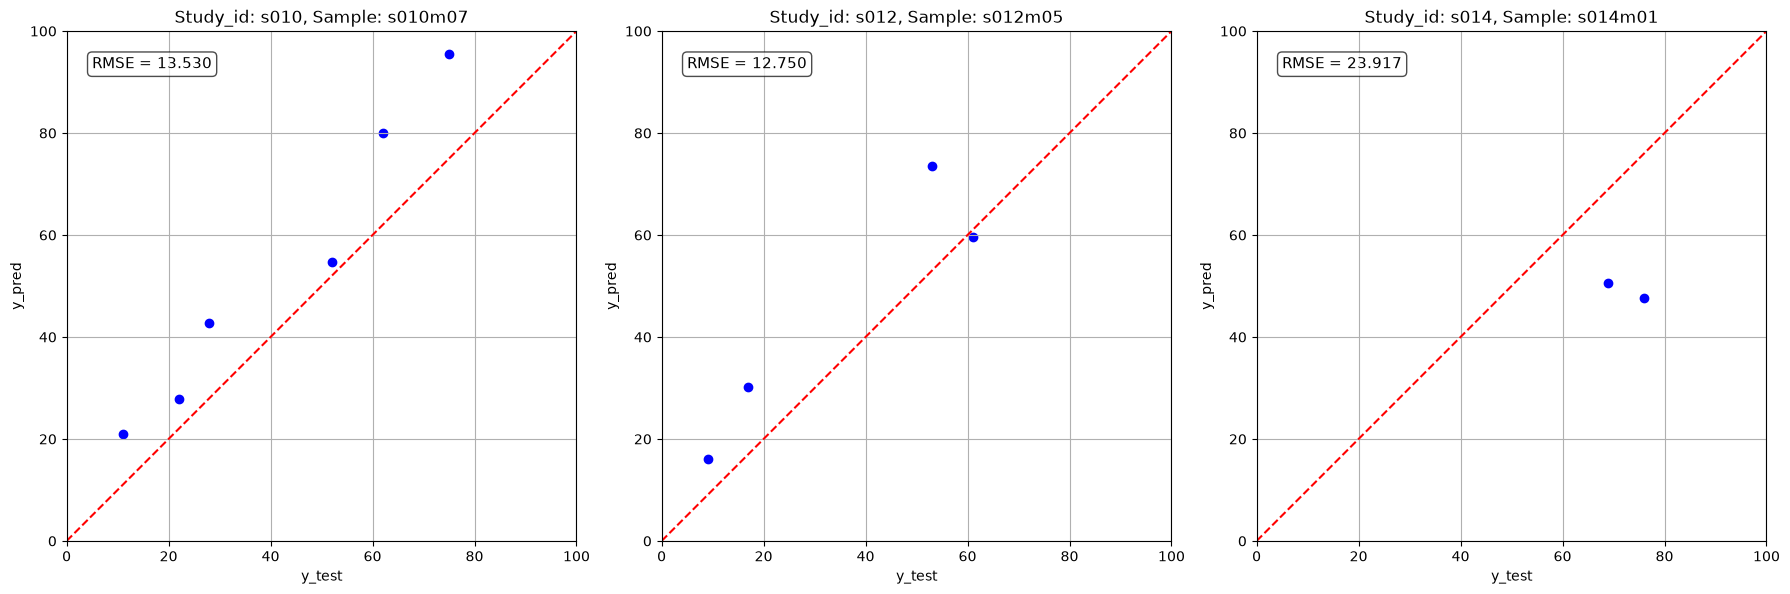

In [126]:
study_ids = df_eval_rf['study_id'].unique().tolist()

lo, hi = 0, 100

fig, axes = plt.subplots(1, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, study_id in zip(axes, study_ids):
    subset = df_eval_rf[df_eval_rf['study_id'] == study_id]
    
 #   pearson_r, _ = pearsonr(subset['y_test'], subset['y_pred'])
    rmse = root_mean_squared_error(subset['y_test'], subset['y_pred'])
    sample = subset['sample_id'].iloc[0]

    ax.scatter(subset['y_test'], subset['y_pred'], color='blue')
    ax.plot([lo, hi], [lo, hi], 'r--')            # corner to corner

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f'Study_id: {study_id}, Sample: {sample}')
    ax.set_xlabel('y_test')
    ax.set_ylabel('y_pred')
    ax.grid(True)
    ax.text(0.05, 0.95, f'RMSE = {rmse:.3f}', transform=ax.transAxes,
            fontsize=11, va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()

## XGBoost

In [129]:
# XGBoost
df_eval_xg = pd.DataFrame({
    'pos': np.arange(len(y_val)),
    'study_id': df_val['study_id'].values,
    'sample_id': df_val['sample_id'].values,
    'y_test': y_val,
    'y_pred': y_val_pred_xg
})

df_eval_xg['error'] = np.abs(df_eval_xg['y_test'] - df_eval_xg['y_pred'])

best_rows2 = df_eval_xg.loc[df_eval_xg.groupby('study_id')['error'].idxmin()]
best_rows_sorted2 = best_rows2.sort_values(by='error', ascending=True)
best_rows_sorted2

,pos,study_id,sample_id,y_test,y_pred,error
93,3,s010,s010m07,52.0,54.708954,2.708954
123,9,s012,s012m05,61.0,73.148552,12.148552
138,11,s014,s014m01,69.0,52.476841,16.523159


## Plot results - XGBoost

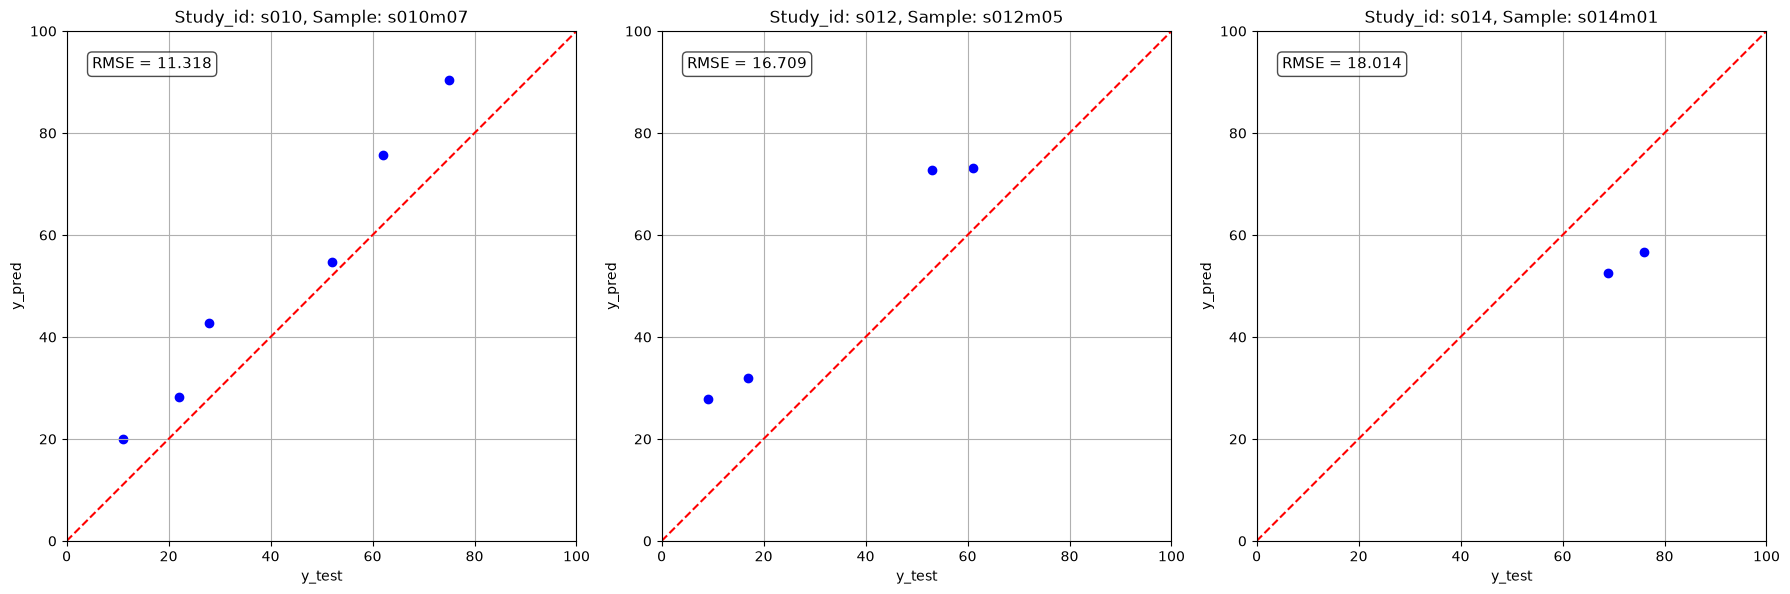

In [132]:
study_ids = df_eval_xg['study_id'].unique().tolist()

lo, hi = 0, 100

fig, axes = plt.subplots(1, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, study_id in zip(axes, study_ids):
    subset = df_eval_xg[df_eval_xg['study_id'] == study_id]
    
 #   pearson_r, _ = pearsonr(subset['y_test'], subset['y_pred'])
    rmse = root_mean_squared_error(subset['y_test'], subset['y_pred'])
    sample = subset['sample_id'].iloc[0]

    ax.scatter(subset['y_test'], subset['y_pred'], color='blue')
    ax.plot([lo, hi], [lo, hi], 'r--')            # corner to corner

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f'Study_id: {study_id}, Sample: {sample}')
    ax.set_xlabel('y_test')
    ax.set_ylabel('y_pred')
    ax.grid(True)
    ax.text(0.05, 0.95, f'RMSE = {rmse:.3f}', transform=ax.transAxes,
            fontsize=11, va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()

## Plot best model

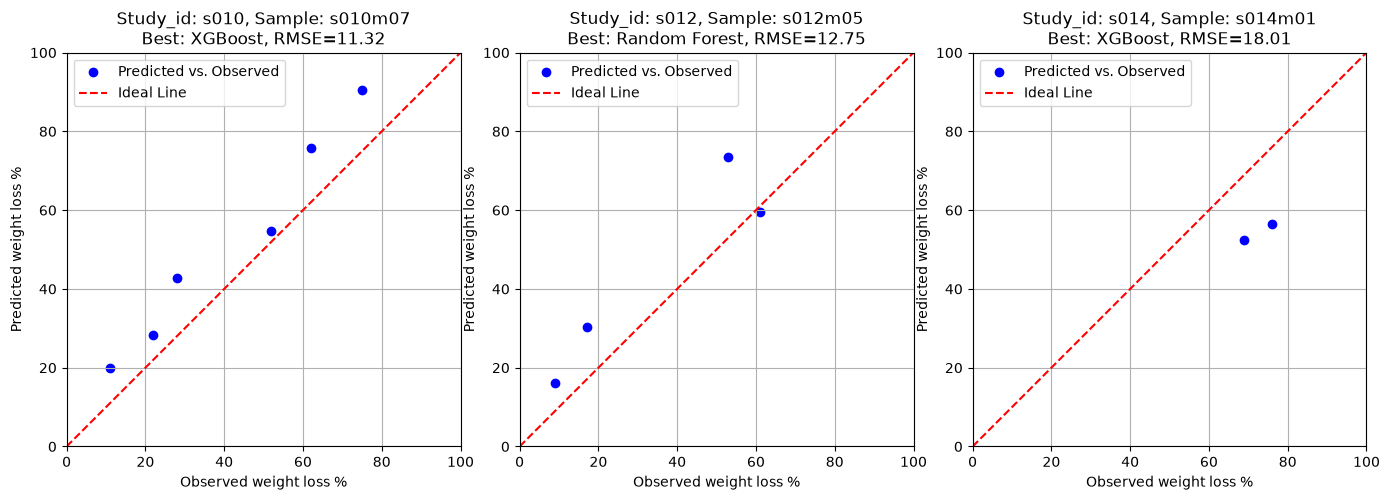

In [135]:
study_ids = df_val['study_id'].unique()          # all validation studies, 3 panels

fig, axes = plt.subplots(1, 3, figsize=(14, 6))

def safe_rmse(d):
    # RMSE, or +inf if the subset is empty
    if len(d) < 1:
        return float('inf')
    return root_mean_squared_error(d['y_test'], d['y_pred'])

lo, hi = 0, 100

for ax, study_id in zip(axes, study_ids):
    subset_xg = df_eval_xg[df_eval_xg['study_id'] == study_id]
    subset_rf = df_eval_rf[df_eval_rf['study_id'] == study_id]

    rmse_xg, rmse_rf = safe_rmse(subset_xg), safe_rmse(subset_rf)

    # Choose the best model by RMSE (lower is better)
    if rmse_xg <= rmse_rf:
        best_subset, best_model, best_rmse = subset_xg, 'XGBoost', rmse_xg
    else:
        best_subset, best_model, best_rmse = subset_rf, 'Random Forest', rmse_rf

    y_obs, y_prd = best_subset['y_test'].to_numpy(), best_subset['y_pred'].to_numpy()
    sample = best_subset['sample_id'].iloc[0]

    ax.scatter(y_obs, y_prd, color='blue', label='Predicted vs. Observed')
    ax.plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
    ax.set_xlabel('Observed weight loss %')
    ax.set_ylabel('Predicted weight loss %')
    ax.set_title(f'Study_id: {study_id}, Sample: {sample}\n'
                 f'Best: {best_model}, RMSE={best_rmse:.2f}')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
fig.subplots_adjust(wspace=0.15)   # distance between panels
plt.savefig('best_unseen.tiff', format='tiff', dpi=300, bbox_inches="tight")
plt.show()

## Performance on experimental data

In [137]:
def part(label, idx, X_final, y_true, src):
    d = src.loc[idx, ['study_id', 'sample_id', 'time_days']].copy()
    d['set'] = label
    d['y'] = np.asarray(y_true)
    d['pred_rf'] = best_rf.predict(X_final)
    d['pred_xgb'] = best_xgb.predict(X_final)      # remove this line if best_xgb is not defined
    return d

all_eval = pd.concat([
    part('train', X_train_final.index, X_train_final, y_train_clean, df_weight),
    part('test',  X_test_final.index,  X_test_final,  y_test,        df_weight),
    part('val',   X_val_final.index,   X_val_final,   y_val,         df_val),
])

s14 = (all_eval[all_eval.study_id == 's014']
       .sort_values('time_days')
       .assign(abs_err_rf=lambda d: abs(d.pred_rf - d.y),
               abs_err_xgb=lambda d: abs(d.pred_xgb - d.y)))
print(s14.round(2).to_string(index=False))

# metrics per set (RMSE / MAE / bias only: R2 and r are not meaningful with so few points)
rows = []
for lab, d in s14.groupby('set'):
    for name, col in [('RF', 'pred_rf'), ('XGB', 'pred_xgb')]:
        rows.append({'set': lab, 'model': name, 'n': len(d),
                     'RMSE': root_mean_squared_error(d.y, d[col]),
                     'MAE': mean_absolute_error(d.y, d[col]),
                     'bias': (d[col] - d.y).mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))

study_id sample_id  time_days   set    y  pred_rf  pred_xgb  abs_err_rf  abs_err_xgb
    s014   s014m01        1.0 train 27.0    32.43 33.740002        5.43         6.74
    s014   s014m01        2.0  test 30.0    32.43 33.740002        2.43         3.74
    s014   s014m01        3.0  test 35.0    38.82 43.970001        3.82         8.97
    s014   s014m01        4.0 train 43.0    38.99 44.009998        4.01         1.01
    s014   s014m01        7.0 train 51.0    47.04 46.500000        3.96         4.50
    s014   s014m01       10.0 train 60.0    52.96 51.400002        7.04         8.60
    s014   s014m01       15.0   val 69.0    50.59 52.480000       18.41        16.52
    s014   s014m01       22.0   val 76.0    47.62 56.610001       28.38        19.39
  set model  n  RMSE   MAE   bias
 test    RF  2  3.20  3.12   3.12
 test   XGB  2  6.87  6.35   6.35
train    RF  4  5.26  5.11  -2.39
train   XGB  4  5.93  5.21  -1.34
  val    RF  2 23.92 23.39 -23.39
  val   XGB  2 18.01 17.96 -17.

## Jaqpot

In [139]:
from jaqpotpy import Jaqpot
from jaqpotpy.datasets import JaqpotTabularDataset
from jaqpotpy.models.sklearn import SklearnModel
from jaqpotpy.doa import Leverage, BoundingBox, MeanVar
from jaqpotpy.models.xgboost import XGBoostModel

In [485]:
df_final.columns

Index(['time_days', 'environment_class', 'polymer_family', 'polymer_wt_pct',
       'additive1_type', 'morphology', 'cellulose_component',
       'weight_loss_pct'],
      dtype='str')

In [487]:
def to_object(df):
    df = df.copy()
    for c in df.columns:
        if str(df[c].dtype) in ('str', 'string', 'string[python]', 'string[pyarrow]'):
            df[c] = df[c].astype(object)
    return df

df_final = to_object(df_final)

print(df_final.dtypes)

time_days              float64
environment_class       object
polymer_family          object
polymer_wt_pct         float64
additive1_type          object
morphology              object
cellulose_component     object
weight_loss_pct        float64
dtype: object


In [489]:
numerical_cols_lst = (
    df_final
    .select_dtypes(include=[np.number])
    .columns
#    .difference(['additive3_percentage_wt'])
    .tolist()
)

categorical_cols_lst = (
    df_final
    .select_dtypes(include=['object', 'category'])
    .columns
    .difference(['polymer_family','morphology', 'cellulose_component'])
    .tolist()
)

exclude_cols = [
    'polymer_family',
    'morphology','cellulose_component'
]

In [491]:
numerical_cols_lst.remove(target)
features_num = numerical_cols_lst
features_cat = categorical_cols_lst

In [493]:
X_train_clean = X_train_clean.drop(columns=exclude_cols, errors='ignore')
df_train = X_train_clean.copy()
# df_train[target] = y_train_clean
df_train[target] = pd.Series(np.asarray(y_train_clean)).clip(0, 100).values

train_dataset = JaqpotTabularDataset(
    df=df_train,
    x_cols=X_train_clean.columns.to_list(),
    y_cols=target,
    task="REGRESSION",
)

In [495]:
X_test = X_test.drop(columns=exclude_cols, errors='ignore')
df_test = X_test.copy()
# df_test[target] = y_test
df_test[target] = pd.Series(np.asarray(y_test)).clip(0, 100).values

test_dataset = JaqpotTabularDataset(
    df=df_test,
    x_cols=X_test.columns.to_list(),
    y_cols=target,
    task="REGRESSION",
)

In [497]:
preprocessing = ColumnTransformer(
    transformers=[
        ('numerical_features', StandardScaler(), features_num),
        ('categorical_features', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='if_binary'), features_cat)
    ],
    remainder='drop',
)

In [499]:
X_train_clean = to_object(X_train_clean)
X_test        = to_object(X_test)

print(X_train_clean.dtypes)     # text columns should now show 'object'

time_days            float64
environment_class     object
polymer_wt_pct       float64
additive1_type        object
dtype: object


In [501]:
X_train_clean = X_train_clean.drop(columns=exclude_cols, errors='ignore')
df_train = X_train_clean.copy()
df_train[target] = y_train_clean

train_dataset = JaqpotTabularDataset(df=df_train, x_cols=X_train_clean.columns.to_list(),
                                     y_cols=target, task="REGRESSION")

X_test = X_test.drop(columns=exclude_cols, errors='ignore')
df_test = X_test.copy()
df_test[target] = y_test

test_dataset = JaqpotTabularDataset(df=df_test, x_cols=X_test.columns.to_list(),
                                    y_cols=target, task="REGRESSION")

In [503]:
model = RandomForestRegressor(random_state=42, max_depth=8, min_samples_leaf=1, max_features=0.5, n_estimators=500)
jaqpot_model = SklearnModel(
    dataset=train_dataset,
    model=model,
    doa=[Leverage(), BoundingBox()],
    preprocess_x=preprocessing,
  )

jaqpot_model.random_seed = 1231
jaqpot_model.fit()

Goodness-of-fit metrics on training set:
{'r2': 0.9350822844399609, 'mae': 4.7764448760934055, 'rmse': 7.982108806321805}


In [505]:
# Perform cross-validation on the training data
jaqpot_model.cross_validate(train_dataset, n_splits=10)

{'r2': 0.7944790862494059,
 'mae': 9.199386826698108,
 'rmse': 13.323399583827571}

In [507]:
# Evaluate the model on the test dataset
jaqpot_model.evaluate(test_dataset)

{'r2': 0.815202157952768, 'mae': 7.026334106278336, 'rmse': 11.823571110829535}

In [509]:
# Conducts a randomization test to assess the model's robustness
jaqpot_model.randomization_test(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    n_iters=10,
)

{'iteration_0': {'Train': {'r2': 0.6001133514431058,
   'mae': 16.570876226768128,
   'rmse': 19.810912562934977},
  'Test': {'r2': -0.2824719136376148,
   'mae': 24.556318028556404,
   'rmse': 31.14756862403297}},
 'iteration_1': {'Train': {'r2': 0.5752017626309254,
   'mae': 17.10216109026154,
   'rmse': 20.418666797503004},
  'Test': {'r2': -0.5374154778506948,
   'mae': 29.92855824516414,
   'rmse': 34.10325594663269}},
 'iteration_2': {'Train': {'r2': 0.6221344322118979,
   'mae': 15.411400907069131,
   'rmse': 19.257712060938825},
  'Test': {'r2': -0.1526065448562548,
   'mae': 22.282328383952077,
   'rmse': 29.52845747395352}},
 'iteration_3': {'Train': {'r2': 0.6789668525611814,
   'mae': 14.383385035037882,
   'rmse': 17.75051539210129},
  'Test': {'r2': -0.750784223789589,
   'mae': 31.746121078709095,
   'rmse': 36.39288894992971}},
 'iteration_4': {'Train': {'r2': 0.5596645694026403,
   'mae': 17.058144107648662,
   'rmse': 20.788724546691206},
  'Test': {'r2': 0.0852897791

In [511]:
doa_predictions = jaqpot_model.predict_doa(test_dataset)
print(doa_predictions)

{'LEVERAGE': [{'h': np.float64(0.16667432284314887), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.1674325948315003), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.16713597754873302), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.16688618788416656), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.05669816647307069), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.056393367545804984), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.05614209330772538), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.05669809761209963), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.05639330980140469), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.05626098765450201), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.12573734682278187), 'hStar': 0.29411764705882354, 'inDoa': True}, {'h': np.float64(0.125081783440601), 'hStar': 0.294

In [513]:
summary = {}
for key in ['LEVERAGE','BOUNDING_BOX']:
    df_doa = pd.DataFrame(doa_predictions[key])
    summary[key] = {
        'n_total': len(df_doa),
        'n_in': int(df_doa['inDoa'].sum()),
        'n_out': int((~df_doa['inDoa']).sum())
    }
summary

{'LEVERAGE': {'n_total': 26, 'n_in': 26, 'n_out': 0},
 'BOUNDING_BOX': {'n_total': 26, 'n_in': 26, 'n_out': 0}}

In [515]:
pred = np.ravel(jaqpot_model.predict(train_dataset))
print(pred.min(), pred.max())

4.9246464646464645 70.87496572348746


## Upload model

In [520]:
jaqpot = Jaqpot()
jaqpot.login()
jaqpot_model.deploy_on_jaqpot(
    jaqpot=jaqpot,
    name="Weight or mass loss regression model for natural polymers A.N.I.P.H.",
    description="Prediction of weight or mass loss percentage of natural polymers.",
    visibility="PUBLIC",
)

Open this URL in your browser and log in:
https://login.jaqpot.org/realms/jaqpot/protocol/openid-connect/auth?client_id=jaqpot-client&response_type=code&redirect_uri=urn:ietf:wg:oauth:2.0:oob&scope=openid email profile&state=random_state_value&nonce=


Enter the authorization code you received:  ········


  2026-11-10 18:34:30,641 - INFO - Model has been successfully uploaded. The url of the model is https://app.jaqpot.org/dashboard/models/2420


In [522]:
df_train[features_num].agg(['min', 'max'])

,time_days,polymer_wt_pct
min,1.0,69.4
max,240.0,100.0


In [524]:
df_train.tail(5)

,time_days,environment_class,polymer_wt_pct,additive1_type,weight_loss_pct
119,240.0,soil,100.0,no_additive,56.0
132,1.0,in_vitro_pbs,99.2,antimicrobial_bioactive,27.0
135,4.0,in_vitro_pbs,99.2,antimicrobial_bioactive,43.0
136,7.0,in_vitro_pbs,99.2,antimicrobial_bioactive,51.0
137,10.0,in_vitro_pbs,99.2,antimicrobial_bioactive,60.0
